# ============================================================
# AgriCLIP + SAM2
# Spatially Clustered Top-K Patch Boxes
# Dataset: VegAnn
#
# Pipeline:
#
# Image
#   ↓
# DINO-RN50 Layer4 spatial features
#   ↓
# VegAnn-specific AgriCLIP linear alignment
#   ↓
# AgriCLIP text-image patch similarity
#   ↓
# Select Top-K patches
#   ↓
# Spatial clustering of selected patches
#   ↓
# Multiple cluster bounding boxes
#   ↓
# Fine-tuned SAM2
#   ↓
# Union of SAM2 masks
#   ↓
# Evaluation
#
# Main hypothesis:
# Preserving spatial separation of AgriCLIP-selected patches
# through multiple boxes may provide better SAM2 prompts
# than one large merged box.
# ============================================================

In [1]:
import os
import sys
import time
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from PIL import Image

from tqdm.auto import tqdm

import torch
import torch.nn.functional as F

from torchvision import transforms

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

from scipy import ndimage

print("Imports successful.")

Imports successful.


In [2]:
# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

MODEL_NAME = (
    "facebook/sam2.1-hiera-tiny"
)

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_cluster_boxes_vegann"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)
print("Output:", OUTPUT_DIR)

Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
Output: /home/zahranadeem/thesis/results/agriclip_cluster_boxes_vegann


In [3]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cuda
GPU: NVIDIA GeForce RTX 4090


In [4]:
#paramters for experiment 
TOP_K = 8

# Spatial connectivity:
# 4 = up/down/left/right
# 8 = also includes diagonal neighbors
CONNECTIVITY = 8

# Expansion around each cluster box
MARGIN = 5

# SAM2 probability threshold
MASK_THRESHOLD = 0.5

print("Top-K:", TOP_K)
print("Connectivity:", CONNECTIVITY)
print("Margin:", MARGIN)
print("Mask threshold", MASK_THRESHOLD)

Top-K: 8
Connectivity: 8
Margin: 5
Mask threshold 0.5


In [5]:
#load vegann 
vegann = load_dataset("simonMadec/Vegann")

print(vegann)




DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})


In [6]:
#Create train/val split 

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print(
    "Training images:",
    len(train_hf)
)

print(
    "Validation images:",
    len(val_hf)
)

Training images: 3020
Validation images: 755


In [7]:


columns = vegann["train"].column_names

IMAGE_KEY = next(
    x
    for x in columns
    if x in [
        "image",
        "images",
        "rgb"
    ]
)

MASK_KEY = next(
    x
    for x in columns
    if x in [
        "mask",
        "masks",
        "label",
        "labels",
        "segmentation_mask"
    ]
)

print("Image column:", IMAGE_KEY)
print("Mask column:", MASK_KEY)

Image column: image
Mask column: mask


In [8]:
#Image and mask helper 


def get_image(
    index,
    split=val_hf
):

    sample = split[index]

    image = sample[IMAGE_KEY]

    if not isinstance(
        image,
        Image.Image
    ):
        image = Image.fromarray(
            np.array(image)
        )

    return image.convert("RGB")


def get_mask(
    index,
    split=val_hf
):

    sample = split[index]

    mask = np.array(
        sample[MASK_KEY]
    )

    mask = (
        mask > 0
    ).astype(np.uint8)

    return mask


print("Helper functions ready.")


Helper functions ready.


Image size: (512, 512)
Mask shape: (512, 512)


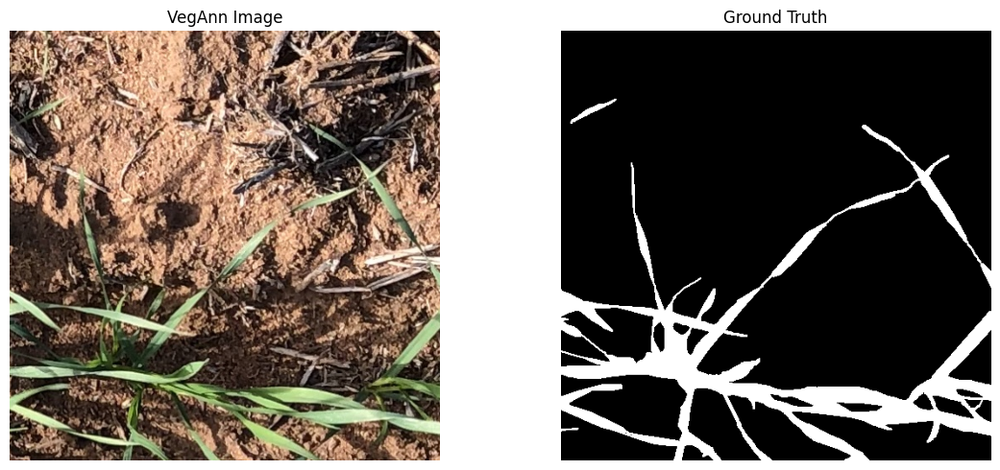

In [9]:
#Visual sanity check 


sample_index = 12

image = get_image(
    sample_index
)

gt_mask = get_mask(
    sample_index
)

print(
    "Image size:",
    image.size
)

print(
    "Mask shape:",
    gt_mask.shape
)

plt.figure(
    figsize=(12, 5)
)

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("VegAnn Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    gt_mask,
    cmap="gray"
)
plt.title("Ground Truth")
plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
#DINO transform 


IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

dino_transform = transforms.Compose([
    
    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])

print("DINO transform ready.")


DINO transform ready.


In [11]:
#DINO transform

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

dino_transform = transforms.Compose([
    
    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])

print("DINO transform ready.")

DINO transform ready.


In [12]:
#Load DINO 

dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_model = dino_model.to(
    device
)

dino_model.eval()

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO loaded.


In [13]:
#Load AgriCLIP alignment code 


ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/"
    "agriclip_sam2/AgriCLIP/"
    "AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(ALIGNMENT_DIR)
    )

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print(
    "AgriCLIP modules imported."
)

AgriCLIP modules imported.


In [14]:
#Loading VegAnn aligenr 

text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50"
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = (
    text_to_concept.linear_aligner
)

print(
    "VegAnn AgriCLIP aligner loaded."
)

print(
    "Aligner W:",
    tuple(aligner.W.shape)
)

print(
    "Aligner b:",
    tuple(aligner.b.shape)
)

VegAnn AgriCLIP aligner loaded.
Aligner W: (512, 2048)
Aligner b: (512,)


In [15]:


captured_feature_map = None


def capture_layer4_output(
    module,
    inputs,
    output
):

    global captured_feature_map

    captured_feature_map = (
        output.detach()
    )


hook_handle = (
    dino_model.layer4.register_forward_hook(
        capture_layer4_output
    )
)

print(
    "DINO layer4 hook registered."
)

DINO layer4 hook registered.


In [16]:

# EXTRACT SPATIAL DINO FEATURES


@torch.no_grad()
def extract_dino_patch_features(
    pil_image
):

    global captured_feature_map

    captured_feature_map = None

    image_tensor = (
        dino_transform(
            pil_image
        )
        .unsqueeze(0)
        .to(device)
    )

    _ = dino_model(
        image_tensor
    )

    if captured_feature_map is None:
        raise RuntimeError(
            "DINO layer4 hook did not "
            "capture a feature map."
        )

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected feature map with "
            "shape (B,C,H,W). Got: "
            f"{captured_feature_map.shape}"
        )

    _, channels, grid_h, grid_w = (
        captured_feature_map.shape
    )

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(
            grid_h * grid_w,
            channels
        )
        .contiguous()
    )

    return (
        patch_features,
        grid_h,
        grid_w
    )


patch_features, grid_h, grid_w = (
    extract_dino_patch_features(
        image
    )
)

print(
    "Grid:",
    grid_h,
    "x",
    grid_w
)

print(
    "Patch features:",
    patch_features.shape
)

Grid: 7 x 7
Patch features: torch.Size([49, 2048])


In [17]:
#Align patches into AGRICLIP space


@torch.no_grad()
def align_patch_features(
    patch_features
):

    patch_features = (
        patch_features
        .float()
        .to(device)
    )

    aligned_features = (
        aligner.get_aligned_representation(
            patch_features
        )
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1
    )

    return aligned_features


aligned_patch_features = (
    align_patch_features(
        patch_features
    )
)

print(
    "Aligned features:",
    aligned_patch_features.shape
)



Aligned features: torch.Size([49, 512])


In [18]:
#Vegetation text prompts 

VEGETATION_PROMPTS = [

    "A crop field populated by healthy plants, captured from a nadir view using a handheld camera.",

    "An agricultural scene showing healthy crops growing in the field, captured from a nadir view using a handheld camera.",

    "A field image containing healthy crop vegetation, captured from a nadir view using a handheld camera.",

    "An aerial agricultural image of dense green crop plants, captured from a nadir view using a handheld camera.",

    "Healthy crop canopy covering the field, captured from a nadir view using a handheld camera.",

    "Agricultural vegetation viewed from above, captured from a nadir view using a handheld camera.",

]

for prompt in VEGETATION_PROMPTS:
    print("+", prompt)

+ A crop field populated by healthy plants, captured from a nadir view using a handheld camera.
+ An agricultural scene showing healthy crops growing in the field, captured from a nadir view using a handheld camera.
+ A field image containing healthy crop vegetation, captured from a nadir view using a handheld camera.
+ An aerial agricultural image of dense green crop plants, captured from a nadir view using a handheld camera.
+ Healthy crop canopy covering the field, captured from a nadir view using a handheld camera.
+ Agricultural vegetation viewed from above, captured from a nadir view using a handheld camera.


In [19]:


@torch.no_grad()
def encode_prompt_set(
    prompts
):

    embeddings = []

    for prompt in prompts:

        embedding = (
            text_to_concept.encode_text(
                [[prompt]]
            )
        )

        if isinstance(
            embedding,
            np.ndarray
        ):
            embedding = (
                torch.from_numpy(
                    embedding
                )
            )

        if not torch.is_tensor(
            embedding
        ):
            raise TypeError(
                f"Unsupported embedding type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    mean_embedding = (
        embeddings.mean(
            dim=0
        )
    )

    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return (
        embeddings,
        mean_embedding
    )


(
    vegetation_text_embeddings,
    vegetation_embedding
) = encode_prompt_set(
    VEGETATION_PROMPTS
)

print(
    "Prompt embeddings:",
    vegetation_text_embeddings.shape
)

print(
    "Mean embedding:",
    vegetation_embedding.shape
)

Prompt embeddings: torch.Size([6, 512])
Mean embedding: torch.Size([512])


In [20]:


@torch.no_grad()
def compute_patch_scores(
    image
):

    patch_features, grid_h, grid_w = (
        extract_dino_patch_features(
            image
        )
    )

    aligned_features = (
        align_patch_features(
            patch_features
        )
    )

    scores = (
        aligned_features
        @ vegetation_embedding
    )

    return (
        scores,
        grid_h,
        grid_w
    )


patch_scores, grid_h, grid_w = (
    compute_patch_scores(
        image
    )
)

scores = (
    patch_scores
    .detach()
    .cpu()
    .numpy()
)

print(
    "Scores shape:",
    scores.shape
)

print(
    "Min:",
    scores.min()
)

print(
    "Max:",
    scores.max()
)

Scores shape: (49,)
Min: 0.38946655
Max: 0.7913691


In [21]:


def get_topk_patches(
    scores,
    top_k,
    grid_h,
    grid_w
):

    topk_indices = (
        np.argsort(
            scores
        )[::-1][:top_k]
    )

    patch_positions = []

    for idx in topk_indices:

        row = idx // grid_w
        col = idx % grid_w

        patch_positions.append(
            (
                int(row),
                int(col)
            )
        )

    return (
        topk_indices,
        patch_positions
    )


(
    topk_indices,
    topk_positions
) = get_topk_patches(
    scores,
    TOP_K,
    grid_h,
    grid_w
)

print(
    "Top-K indices:",
    topk_indices
)

print(
    "Top-K positions:"
)

for idx, pos in zip(
    topk_indices,
    topk_positions
):

    print(
        f"Patch {idx:2d} "
        f"→ row={pos[0]}, col={pos[1]} "
        f"score={scores[idx]:.4f}"
    )

Top-K indices: [ 1 22 39  0 41  6 46 29]
Top-K positions:
Patch  1 → row=0, col=1 score=0.7914
Patch 22 → row=3, col=1 score=0.7648
Patch 39 → row=5, col=4 score=0.7579
Patch  0 → row=0, col=0 score=0.7574
Patch 41 → row=5, col=6 score=0.7564
Patch  6 → row=0, col=6 score=0.7521
Patch 46 → row=6, col=4 score=0.7502
Patch 29 → row=4, col=1 score=0.7491


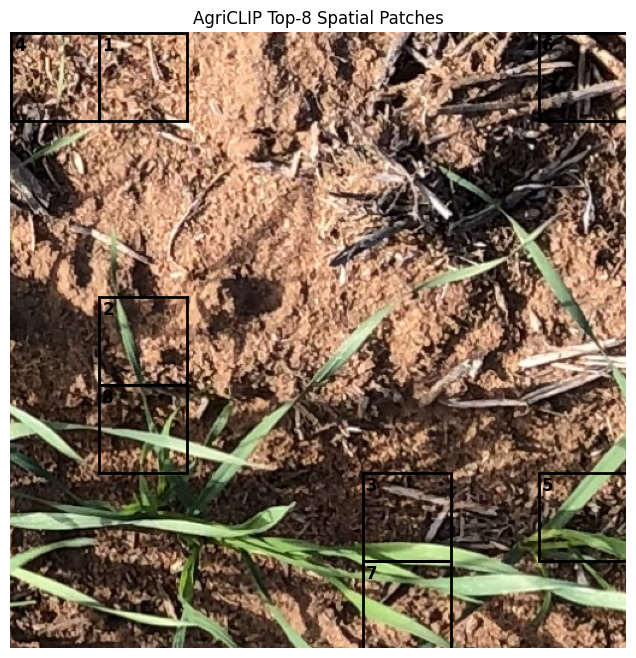

In [22]:
#Visualize top patches 

H, W = image.size[1], image.size[0]

patch_h = H / grid_h
patch_w = W / grid_w

fig, ax = plt.subplots(
    figsize=(8, 8)
)

ax.imshow(image)

for rank, idx in enumerate(
    topk_indices
):

    row = idx // grid_w
    col = idx % grid_w

    x1 = col * patch_w
    y1 = row * patch_h

    rect = patches.Rectangle(
        (x1, y1),
        patch_w,
        patch_h,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        x1 + 3,
        y1 + 15,
        str(rank + 1),
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    f"AgriCLIP Top-{TOP_K} Spatial Patches"
)

ax.axis("off")

plt.show()

In [23]:

# CREATE TOP-K SPATIAL GRID


selected_grid = np.zeros(
    (grid_h, grid_w),
    dtype=np.uint8
)

for idx in topk_indices:

    row = idx // grid_w
    col = idx % grid_w

    selected_grid[
        row,
        col
    ] = 1

print(
    selected_grid
)

[[1 1 0 0 0 0 1]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0]
 [0 1 0 0 0 0 0]
 [0 0 0 0 1 0 1]
 [0 0 0 0 1 0 0]]


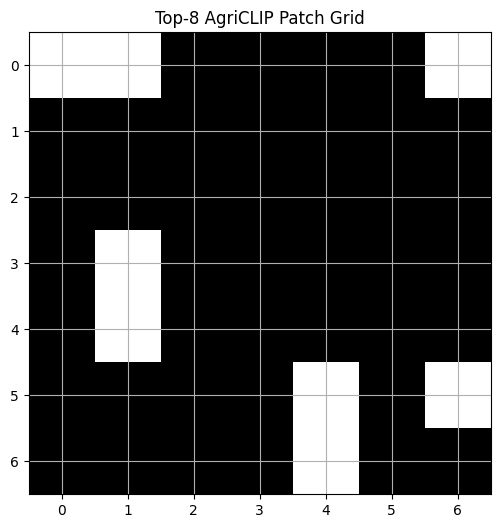

In [24]:
#Visualuze spatial clsuters 


plt.figure(
    figsize=(6, 6)
)

plt.imshow(
    selected_grid,
    cmap="gray"
)

plt.title(
    f"Top-{TOP_K} AgriCLIP Patch Grid"
)

plt.xticks(
    range(grid_w)
)

plt.yticks(
    range(grid_h)
)

plt.grid()

plt.show()

In [25]:
#spatial clustering 


def find_spatial_clusters(
    selected_grid,
    connectivity=8
):

    if connectivity == 4:

        structure = np.array([
            [0, 1, 0],
            [1, 1, 1],
            [0, 1, 0]
        ])

    elif connectivity == 8:

        structure = np.ones(
            (3, 3),
            dtype=np.uint8
        )

    else:

        raise ValueError(
            "Connectivity must be "
            "4 or 8."
        )

    labeled_grid, num_clusters = (
        ndimage.label(
            selected_grid,
            structure=structure
        )
    )

    clusters = []

    for cluster_id in range(
        1,
        num_clusters + 1
    ):

        positions = np.argwhere(
            labeled_grid == cluster_id
        )

        clusters.append(
            positions
        )

    return (
        labeled_grid,
        clusters
    )


(
    labeled_grid,
    clusters
) = find_spatial_clusters(
    selected_grid,
    CONNECTIVITY
)

print(
    "Number of spatial clusters:",
    len(clusters)
)

for cluster_id, positions in enumerate(
    clusters,
    start=1
):

    print(
        f"Cluster {cluster_id}:"
    )

    print(
        positions
    )

Number of spatial clusters: 5
Cluster 1:
[[0 0]
 [0 1]]
Cluster 2:
[[0 6]]
Cluster 3:
[[3 1]
 [4 1]]
Cluster 4:
[[5 4]
 [6 4]]
Cluster 5:
[[5 6]]


In [26]:
#converting each clsuter into one SAM2 box 


def clusters_to_boxes(
    clusters,
    image_width,
    image_height,
    grid_h,
    grid_w,
    margin=5
):

    patch_h = (
        image_height / grid_h
    )

    patch_w = (
        image_width / grid_w
    )

    cluster_boxes = []

    for positions in clusters:

        rows = positions[:, 0]
        cols = positions[:, 1]

        row_min = rows.min()
        row_max = rows.max()

        col_min = cols.min()
        col_max = cols.max()

        x1 = int(
            col_min * patch_w
        )

        y1 = int(
            row_min * patch_h
        )

        x2 = int(
            (col_max + 1) * patch_w
        )

        y2 = int(
            (row_max + 1) * patch_h
        )

        # Add margin
        x1 = max(
            0,
            x1 - margin
        )

        y1 = max(
            0,
            y1 - margin
        )

        x2 = min(
            image_width - 1,
            x2 + margin
        )

        y2 = min(
            image_height - 1,
            y2 + margin
        )

        cluster_boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )

    return np.array(
        cluster_boxes,
        dtype=np.int32
    )


cluster_boxes = clusters_to_boxes(
    clusters=clusters,
    image_width=W,
    image_height=H,
    grid_h=grid_h,
    grid_w=grid_w,
    margin=MARGIN
)

print(
    "Cluster boxes:"
)

for i, box in enumerate(
    cluster_boxes
):

    print(
        f"Box {i+1}: {box}"
    )

Cluster boxes:
Box 1: [  0   0 151  78]
Box 2: [433   0 511  78]
Box 3: [ 68 214 151 370]
Box 4: [287 360 370 511]
Box 5: [433 360 511 443]


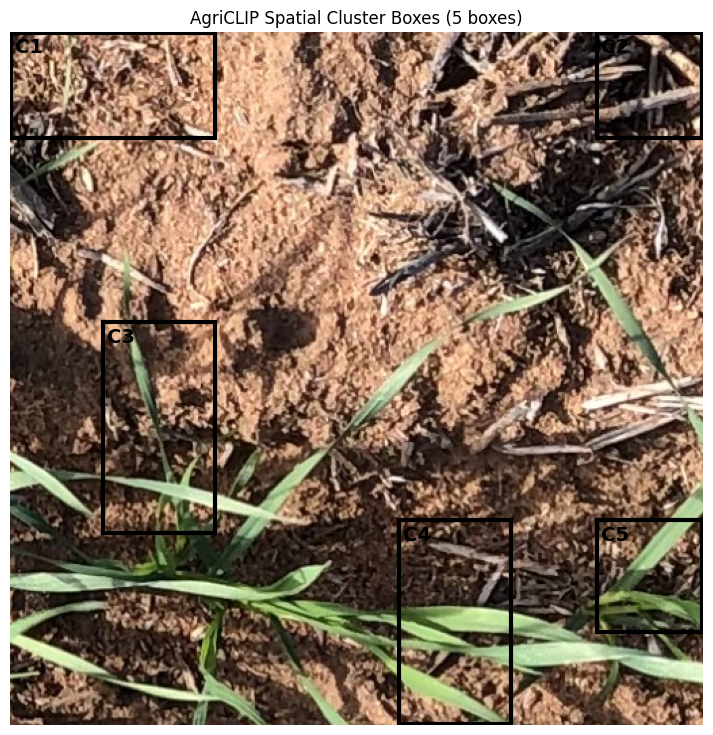

In [27]:
#visualize cluster boxes 


fig, ax = plt.subplots(
    figsize=(9, 9)
)

ax.imshow(image)

for i, box in enumerate(
    cluster_boxes
):

    x1, y1, x2, y2 = box

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=3
    )

    ax.add_patch(rect)

    ax.text(
        x1 + 3,
        y1 + 15,
        f"C{i+1}",
        fontsize=14,
        fontweight="bold"
    )

ax.set_title(
    f"AgriCLIP Spatial Cluster Boxes "
    f"({len(cluster_boxes)} boxes)"
)

ax.axis("off")

plt.show()

In [28]:
#Previous megred box function for comparision 


def create_merged_box(
    topk_indices,
    image_width,
    image_height,
    grid_h,
    grid_w,
    margin=5
):

    patch_h = (
        image_height / grid_h
    )

    patch_w = (
        image_width / grid_w
    )

    boxes = []

    for idx in topk_indices:

        row = idx // grid_w
        col = idx % grid_w

        x1 = int(
            col * patch_w
        )

        y1 = int(
            row * patch_h
        )

        x2 = int(
            (col + 1) * patch_w
        )

        y2 = int(
            (row + 1) * patch_h
        )

        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )

    boxes = np.array(
        boxes
    )

    xmin = boxes[:, 0].min()
    ymin = boxes[:, 1].min()

    xmax = boxes[:, 2].max()
    ymax = boxes[:, 3].max()

    xmin = max(
        0,
        xmin - margin
    )

    ymin = max(
        0,
        ymin - margin
    )

    xmax = min(
        image_width - 1,
        xmax + margin
    )

    ymax = min(
        image_height - 1,
        ymax + margin
    )

    return np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )


merged_box = create_merged_box(
    topk_indices,
    W,
    H,
    grid_h,
    grid_w,
    MARGIN
)

print(
    "Merged box:",
    merged_box
)

Merged box: [  0   0 511 511]


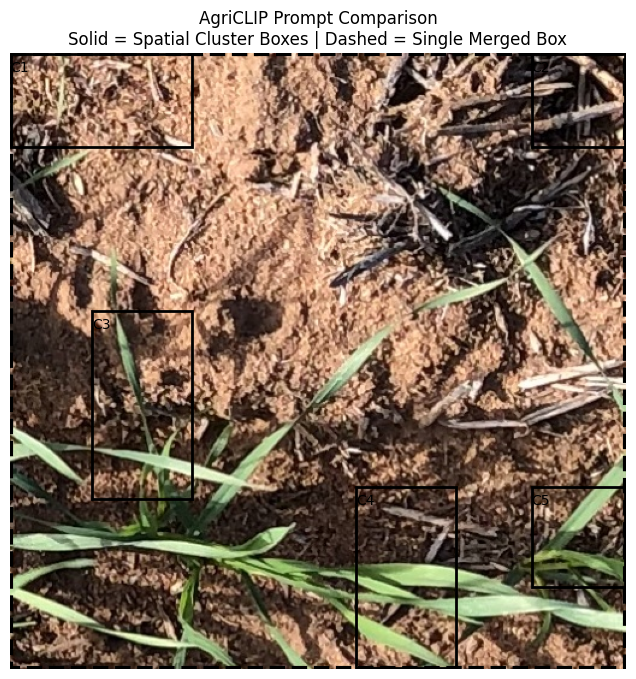

In [29]:
#Comapre both merged vs cluster box 


fig, ax = plt.subplots(
    figsize=(10, 8)
)

ax.imshow(image)

# Cluster boxes
for i, box in enumerate(
    cluster_boxes
):

    x1, y1, x2, y2 = box

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1 + 15,
        f"C{i+1}"
    )

# Merged box
x1, y1, x2, y2 = merged_box

rect = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    fill=False,
    linewidth=3,
    linestyle="--"
)

ax.add_patch(rect)

ax.set_title(
    "AgriCLIP Prompt Comparison\n"
    "Solid = Spatial Cluster Boxes | "
    "Dashed = Single Merged Box"
)

ax.axis("off")

plt.show()

In [30]:
#Loasding Fine tuned SAM2 

# ============================================================
# LOAD SAM2
# ============================================================

sam2_processor = (
    Sam2Processor.from_pretrained(
        MODEL_NAME
    )
)

sam2_model = (
    Sam2Model.from_pretrained(
        MODEL_NAME
    )
)

sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu"
)

print(
    "Checkpoint type:",
    type(sam2_checkpoint)
)

if (
    isinstance(
        sam2_checkpoint,
        dict
    )
    and
    "mask_decoder_state_dict"
    in sam2_checkpoint
):

    mask_decoder_state_dict = (
        sam2_checkpoint[
            "mask_decoder_state_dict"
        ]
    )

elif isinstance(
    sam2_checkpoint,
    dict
):

    mask_decoder_state_dict = (
        sam2_checkpoint
    )

else:

    raise TypeError(
        "Unsupported SAM2 checkpoint."
    )


load_result = (
    sam2_model.mask_decoder.load_state_dict(
        mask_decoder_state_dict,
        strict=True
    )
)

sam2_model = sam2_model.to(
    device
)

sam2_model.eval()

print(
    "Fine-tuned SAM2 loaded."
)

print(load_result)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Checkpoint type: <class 'dict'>
Fine-tuned SAM2 loaded.
<All keys matched successfully>


In [31]:
#SAM2 single box prediction 


@torch.no_grad()
def sam2_predict_single_box(
    image,
    box,
    threshold=0.5
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt"
    )

    inputs = {
        k: (
            v.to(device)
            if torch.is_tensor(v)
            else v
        )
        for k, v in inputs.items()
    }

    outputs = sam2_model(
        **inputs
    )

    best_idx = (
        outputs.iou_scores[
            0,
            0
        ]
        .argmax()
        .item()
    )

    logits = outputs.pred_masks[
        0,
        0,
        best_idx
    ]

    probability = torch.sigmoid(
        logits
    )

    height = int(
        inputs[
            "original_sizes"
        ][0, 0].item()
    )

    width = int(
        inputs[
            "original_sizes"
        ][0, 1].item()
    )

    probability = F.interpolate(
        probability[None, None],
        size=(height, width),
        mode="bilinear",
        align_corners=False
    )[0, 0]

    prediction = (
        probability >= threshold
    ).cpu().numpy().astype(
        np.uint8
    )

    confidence = float(
        outputs.iou_scores[
            0,
            0,
            best_idx
        ].item()
    )

    return (
        prediction,
        confidence
    )

In [32]:
#Predict from MULTIPLE boxes 

@torch.no_grad()
def sam2_predict_cluster_boxes(
    image,
    cluster_boxes,
    threshold=0.5
):

    H = image.size[1]
    W = image.size[0]

    union_mask = np.zeros(
        (H, W),
        dtype=np.uint8
    )

    individual_masks = []
    confidences = []

    for box in cluster_boxes:

        prediction, confidence = (
            sam2_predict_single_box(
                image,
                box,
                threshold=threshold
            )
        )

        individual_masks.append(
            prediction
        )

        confidences.append(
            confidence
        )

        # Union the predictions
        union_mask = np.logical_or(
            union_mask,
            prediction
        ).astype(
            np.uint8
        )

    return (
        union_mask,
        individual_masks,
        confidences
    )

In [33]:
#Test multiple cluster boxes on 1 image 


start_time = time.perf_counter()

cluster_prediction, individual_masks, confidences = (
    sam2_predict_cluster_boxes(
        image,
        cluster_boxes,
        MASK_THRESHOLD
    )
)

elapsed = (
    time.perf_counter()
    - start_time
)

print(
    "Number of cluster boxes:",
    len(cluster_boxes)
)

print(
    "SAM2 confidences:",
    confidences
)

print(
    "Union foreground pixels:",
    cluster_prediction.sum()
)

print(
    f"Runtime: {elapsed:.4f} seconds"
)


Number of cluster boxes: 5
SAM2 confidences: [0.8951975703239441, 0.8022895455360413, 0.8803346157073975, 0.9093813300132751, 0.8741683959960938]
Union foreground pixels: 36397
Runtime: 0.2505 seconds


In [34]:
#Metrics 
def compute_binary_metrics(
    prediction,
    ground_truth
):

    prediction = (
        prediction.astype(bool)
    )

    ground_truth = (
        ground_truth.astype(bool)
    )

    intersection = np.logical_and(
        prediction,
        ground_truth
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth
    ).sum()

    pred_pixels = (
        prediction.sum()
    )

    gt_pixels = (
        ground_truth.sum()
    )

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    dice_denominator = (
        pred_pixels + gt_pixels
    )

    dice = (
        2.0 * intersection
        / dice_denominator
        if dice_denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall)
    }


cluster_metrics = (
    compute_binary_metrics(
        cluster_prediction,
        gt_mask
    )
)

print(
    "Cluster-box SAM2 results:"
)

for key, value in (
    cluster_metrics.items()
):

    print(
        f"{key:>12}: "
        f"{value:.4f}"
    )

Cluster-box SAM2 results:
         iou: 0.8189
        dice: 0.9004
   precision: 0.8474
      recall: 0.9605


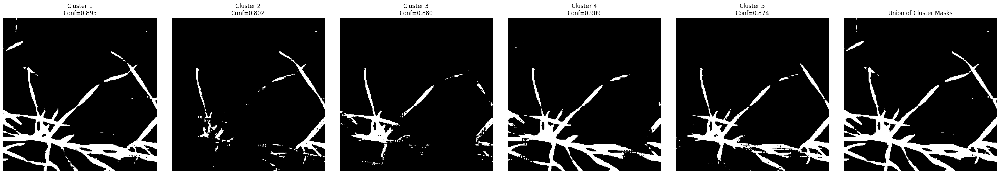

In [35]:
#Visualize individyual mask + Union 


n = len(individual_masks)

fig, axes = plt.subplots(
    1,
    n + 1,
    figsize=(5 * (n + 1), 5)
)

if n == 1:
    axes = [axes]

for i, mask in enumerate(
    individual_masks
):

    axes[i].imshow(
        mask,
        cmap="gray"
    )

    axes[i].set_title(
        f"Cluster {i+1}\n"
        f"Conf={confidences[i]:.3f}"
    )

    axes[i].axis("off")


axes[-1].imshow(
    cluster_prediction,
    cmap="gray"
)

axes[-1].set_title(
    "Union of Cluster Masks"
)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

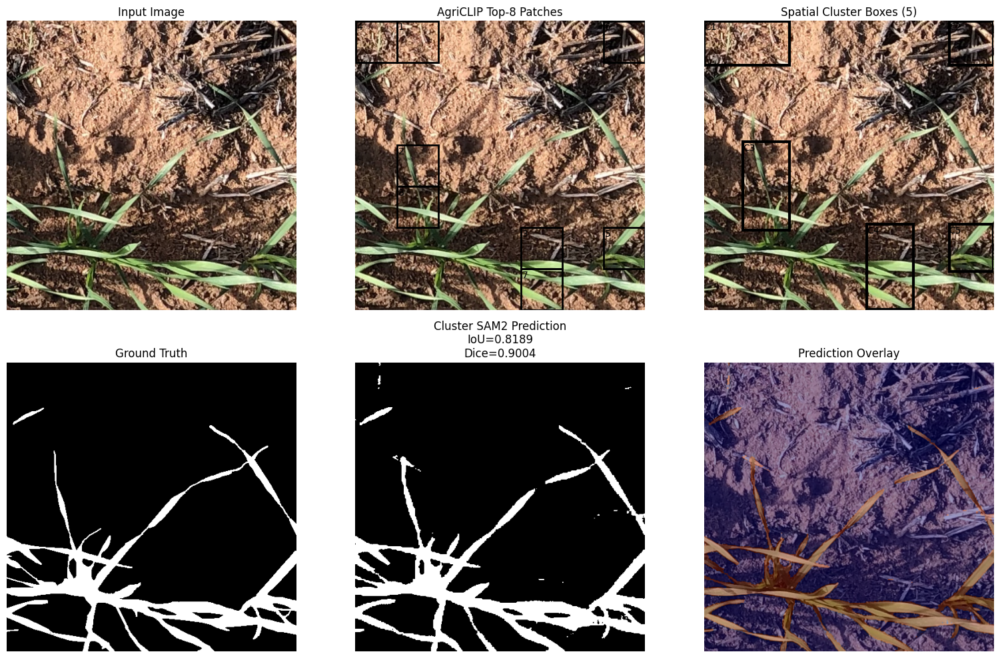

In [36]:
#Final visualization for one image 


fig, ax = plt.subplots(
    2,
    3,
    figsize=(16, 10)
)

# Input
ax[0, 0].imshow(image)
ax[0, 0].set_title(
    "Input Image"
)
ax[0, 0].axis("off")


# Top-K patches
ax[0, 1].imshow(image)

for rank, idx in enumerate(
    topk_indices
):

    row = idx // grid_w
    col = idx % grid_w

    x1 = col * patch_w
    y1 = row * patch_h

    rect = patches.Rectangle(
        (x1, y1),
        patch_w,
        patch_h,
        fill=False,
        linewidth=2
    )

    ax[0, 1].add_patch(rect)

    ax[0, 1].text(
        x1 + 2,
        y1 + 15,
        str(rank + 1)
    )

ax[0, 1].set_title(
    f"AgriCLIP Top-{TOP_K} Patches"
)

ax[0, 1].axis("off")


# Cluster boxes
ax[0, 2].imshow(image)

for i, box in enumerate(
    cluster_boxes
):

    x1, y1, x2, y2 = box

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=3
    )

    ax[0, 2].add_patch(
        rect
    )

    ax[0, 2].text(
        x1,
        y1 + 15,
        f"C{i+1}"
    )

ax[0, 2].set_title(
    f"Spatial Cluster Boxes "
    f"({len(cluster_boxes)})"
)

ax[0, 2].axis("off")


# Ground truth
ax[1, 0].imshow(
    gt_mask,
    cmap="gray"
)

ax[1, 0].set_title(
    "Ground Truth"
)

ax[1, 0].axis("off")


# Prediction
ax[1, 1].imshow(
    cluster_prediction,
    cmap="gray"
)

ax[1, 1].set_title(
    f"Cluster SAM2 Prediction\n"
    f"IoU={cluster_metrics['iou']:.4f}\n"
    f"Dice={cluster_metrics['dice']:.4f}"
)

ax[1, 1].axis("off")


# Overlay
ax[1, 2].imshow(image)

ax[1, 2].imshow(
    cluster_prediction,
    cmap="jet",
    alpha=0.4
)

ax[1, 2].set_title(
    "Prediction Overlay"
)

ax[1, 2].axis("off")

plt.tight_layout()
plt.show()

In [37]:
#cluster box localization 

def boxes_to_mask(
    boxes,
    image_width,
    image_height
):

    mask = np.zeros(
        (image_height, image_width),
        dtype=np.uint8
    )

    for box in boxes:

        x1, y1, x2, y2 = box

        mask[
            y1:y2,
            x1:x2
        ] = 1

    return mask


cluster_box_mask = boxes_to_mask(
    cluster_boxes,
    W,
    H
)

merged_box_mask = boxes_to_mask(
    np.array([
        merged_box
    ]),
    W,
    H
)

cluster_box_metrics = (
    compute_binary_metrics(
        cluster_box_mask,
        gt_mask
    )
)

merged_box_metrics = (
    compute_binary_metrics(
        merged_box_mask,
        gt_mask
    )
)

print(
    "Cluster-box localization IoU:",
    cluster_box_metrics["iou"]
)

print(
    "Merged-box localization IoU:",
    merged_box_metrics["iou"]
)

Cluster-box localization IoU: 0.11731013132952392
Merged-box localization IoU: 0.12236711666022361


In [38]:
#Comparsion on one image 


comparison_one = pd.DataFrame({

    "Method": [
        "AgriCLIP Single Merged Box",
        "AgriCLIP Spatial Cluster Boxes"
    ],

    "Box IoU": [
        merged_box_metrics["iou"],
        cluster_box_metrics["iou"]
    ],

    "SAM2 IoU": [
        np.nan,
        cluster_metrics["iou"]
    ],

    "SAM2 Dice": [
        np.nan,
        cluster_metrics["dice"]
    ],

    "Number of Boxes": [
        1,
        len(cluster_boxes)
    ]
})

comparison_one

,Method,Box IoU,SAM2 IoU,SAM2 Dice,Number of Boxes
0,AgriCLIP Single Merged Box,0.122367,NaN,NaN,1
1,AgriCLIP Spatial Cluster Boxes,0.117310,0.818903,0.900436,5


## COMPLETE VALIDATION SET EVALUATION 

In [39]:


@torch.no_grad()
def generate_agriclip_cluster_boxes(
    image,
    top_k=8,
    connectivity=8,
    margin=5
):

    # --------------------------------------------------------
    # 1. Extract DINO spatial features
    # --------------------------------------------------------

    patch_features, grid_h, grid_w = (
        extract_dino_patch_features(
            image
        )
    )

    # --------------------------------------------------------
    # 2. Project into AgriCLIP concept space
    # --------------------------------------------------------

    aligned_features = (
        align_patch_features(
            patch_features
        )
    )

    # --------------------------------------------------------
    # 3. Calculate patch-text similarity
    # --------------------------------------------------------

    patch_scores = (
        aligned_features
        @ vegetation_embedding
    )

    scores = (
        patch_scores
        .cpu()
        .numpy()
    )

    # --------------------------------------------------------
    # 4. Top-K
    # --------------------------------------------------------

    topk_indices = (
        np.argsort(scores)[::-1][:top_k]
    )

    # --------------------------------------------------------
    # 5. Create spatial grid
    # --------------------------------------------------------

    selected_grid = np.zeros(
        (grid_h, grid_w),
        dtype=np.uint8
    )

    for idx in topk_indices:

        row = idx // grid_w
        col = idx % grid_w

        selected_grid[
            row,
            col
        ] = 1

    # --------------------------------------------------------
    # 6. Spatial clustering
    # --------------------------------------------------------

    labeled_grid, clusters = (
        find_spatial_clusters(
            selected_grid,
            connectivity
        )
    )

    # --------------------------------------------------------
    # 7. Convert clusters to boxes
    # --------------------------------------------------------

    W = image.size[0]
    H = image.size[1]

    cluster_boxes = (
        clusters_to_boxes(
            clusters,
            W,
            H,
            grid_h,
            grid_w,
            margin
        )
    )

    return {
        "patch_scores": scores,
        "topk_indices": topk_indices,
        "selected_grid": selected_grid,
        "labeled_grid": labeled_grid,
        "clusters": clusters,
        "cluster_boxes": cluster_boxes,
        "grid_h": grid_h,
        "grid_w": grid_w
    }

In [40]:
# ============================================================
# TEST REUSABLE LOCALIZATION FUNCTION
# ============================================================

localization = (
    generate_agriclip_cluster_boxes(
        image,
        top_k=TOP_K,
        connectivity=CONNECTIVITY,
        margin=MARGIN
    )
)

print(
    "Top-K:",
    localization[
        "topk_indices"
    ]
)

print(
    "Number of clusters:",
    len(
        localization[
            "clusters"
        ]
    )
)

print(
    "Cluster boxes:"
)

print(
    localization[
        "cluster_boxes"
    ]
)

Top-K: [ 1 22 39  0 41  6 46 29]
Number of clusters: 5
Cluster boxes:
[[  0   0 151  78]
 [433   0 511  78]
 [ 68 214 151 370]
 [287 360 370 511]
 [433 360 511 443]]


In [41]:
#Full val output directories 



VAL_OUTPUT_DIR = (
    OUTPUT_DIR
    / "validation"
)

MASK_DIR = (
    VAL_OUTPUT_DIR
    / "predictions"
)

BOX_DIR = (
    VAL_OUTPUT_DIR
    / "cluster_boxes"
)

PATCH_DIR = (
    VAL_OUTPUT_DIR
    / "patch_scores"
)

MASK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BOX_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PATCH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(
    VAL_OUTPUT_DIR
)


/home/zahranadeem/thesis/results/agriclip_cluster_boxes_vegann/validation


In [42]:
# ============================================================
# FULL VALIDATION:
# AGRICLIP SPATIAL CLUSTER BOXES + SAM2
# ============================================================

results = []

total_start = time.perf_counter()

for idx in tqdm(
    range(len(val_hf))
):

    image = get_image(
        idx,
        split=val_hf
    )

    gt_mask = get_mask(
        idx,
        split=val_hf
    )

    try:

        image_start = (
            time.perf_counter()
        )

        # ----------------------------------------------------
        # AgriCLIP localization
        # ----------------------------------------------------

        localization = (
            generate_agriclip_cluster_boxes(
                image,
                top_k=TOP_K,
                connectivity=CONNECTIVITY,
                margin=MARGIN
            )
        )

        cluster_boxes = (
            localization[
                "cluster_boxes"
            ]
        )

        # ----------------------------------------------------
        # Cluster-box localization mask
        # ----------------------------------------------------

        box_mask = boxes_to_mask(
            cluster_boxes,
            image.size[0],
            image.size[1]
        )

        box_metrics = (
            compute_binary_metrics(
                box_mask,
                gt_mask
            )
        )

        # ----------------------------------------------------
        # SAM2 segmentation
        # ----------------------------------------------------

        pred_mask, individual_masks, confidences = (
            sam2_predict_cluster_boxes(
                image,
                cluster_boxes,
                MASK_THRESHOLD
            )
        )

        # ----------------------------------------------------
        # Segmentation metrics
        # ----------------------------------------------------

        metrics = (
            compute_binary_metrics(
                pred_mask,
                gt_mask
            )
        )

        image_time = (
            time.perf_counter()
            - image_start
        )

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        results.append({

            "image_id": idx,

            "num_clusters": len(
                cluster_boxes
            ),

            "box_iou": (
                box_metrics["iou"]
            ),

            "iou": (
                metrics["iou"]
            ),

            "dice": (
                metrics["dice"]
            ),

            "precision": (
                metrics["precision"]
            ),

            "recall": (
                metrics["recall"]
            ),

            "mean_sam2_confidence": (
                np.mean(confidences)
                if len(confidences) > 0
                else 0.0
            ),

            "max_sam2_confidence": (
                np.max(confidences)
                if len(confidences) > 0
                else 0.0
            ),

            "runtime_seconds": (
                image_time
            )
        })

        # ----------------------------------------------------
        # Save prediction
        # ----------------------------------------------------

        cv2.imwrite(
            str(
                MASK_DIR /
                f"{idx:04d}.png"
            ),
            pred_mask * 255
        )

        # ----------------------------------------------------
        # Save boxes
        # ----------------------------------------------------

        np.save(
            BOX_DIR /
            f"{idx:04d}.npy",
            cluster_boxes
        )

        # ----------------------------------------------------
        # Save patch scores
        # ----------------------------------------------------

        np.save(
            PATCH_DIR /
            f"{idx:04d}.npy",
            localization[
                "patch_scores"
            ]
        )

    except Exception as e:

        print(
            f"Failed at image {idx}: {e}"
        )

        raise e


total_time = (
    time.perf_counter()
    - total_start
)

print(
    "Validation complete."
)

print(
    f"Total runtime: "
    f"{total_time:.2f} seconds"
)

  0%|          | 0/755 [00:00<?, ?it/s]

Validation complete.
Total runtime: 72.09 seconds


In [43]:
#saving results 

results_df = pd.DataFrame(
    results
)

csv_path = (
    VAL_OUTPUT_DIR
    / "cluster_box_validation_metrics.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print(
    "Saved:",
    csv_path
)

results_df.head()

Saved: /home/zahranadeem/thesis/results/agriclip_cluster_boxes_vegann/validation/cluster_box_validation_metrics.csv


,image_id,num_clusters,box_iou,iou,dice,precision,recall,mean_sam2_confidence,max_sam2_confidence,runtime_seconds
0,0,1,0.254117,0.592228,0.743899,0.975537,0.601156,0.877957,0.877957,0.032630
1,1,2,0.240851,0.373884,0.544273,0.988391,0.375533,0.798947,0.873643,0.058801
2,2,6,0.082662,0.804638,0.891745,0.894714,0.888795,0.932159,0.944793,0.156574
3,3,4,0.226869,0.556116,0.714749,0.955812,0.570791,0.652156,0.842431,0.109493
4,4,3,0.231386,0.488286,0.656173,0.978304,0.493632,0.834893,0.903682,0.092020


In [44]:


mean_results = (
    results_df
    .mean(
        numeric_only=True
    )
)

print(
    "================================================"
)

print(
    "AGRlCLIP CLUSTER BOX RESULTS — VEGANN"
)

print(
    "================================================"
)

print(
    f"Images: "
    f"{len(results_df)}"
)

print(
    f"Mean number of clusters: "
    f"{mean_results['num_clusters']:.2f}"
)

print(
    f"Mean cluster-box IoU: "
    f"{mean_results['box_iou'] * 100:.2f}%"
)

print(
    f"Mean SAM2 IoU: "
    f"{mean_results['iou'] * 100:.2f}%"
)

print(
    f"Mean Dice: "
    f"{mean_results['dice'] * 100:.2f}%"
)

print(
    f"Mean Precision: "
    f"{mean_results['precision'] * 100:.2f}%"
)

print(
    f"Mean Recall: "
    f"{mean_results['recall'] * 100:.2f}%"
)

print(
    f"Mean SAM2 confidence: "
    f"{mean_results['mean_sam2_confidence'] * 100:.2f}%"
)

print(
    f"Mean runtime/image: "
    f"{mean_results['runtime_seconds']:.4f} sec"
)

AGRlCLIP CLUSTER BOX RESULTS — VEGANN
Images: 755
Mean number of clusters: 3.15
Mean cluster-box IoU: 21.30%
Mean SAM2 IoU: 70.62%
Mean Dice: 80.30%
Mean Precision: 90.84%
Mean Recall: 75.41%
Mean SAM2 confidence: 84.25%
Mean runtime/image: 0.0814 sec


num_clusters
1     51
2    199
3    218
4    179
5     88
6     18
7      2
Name: count, dtype: int64


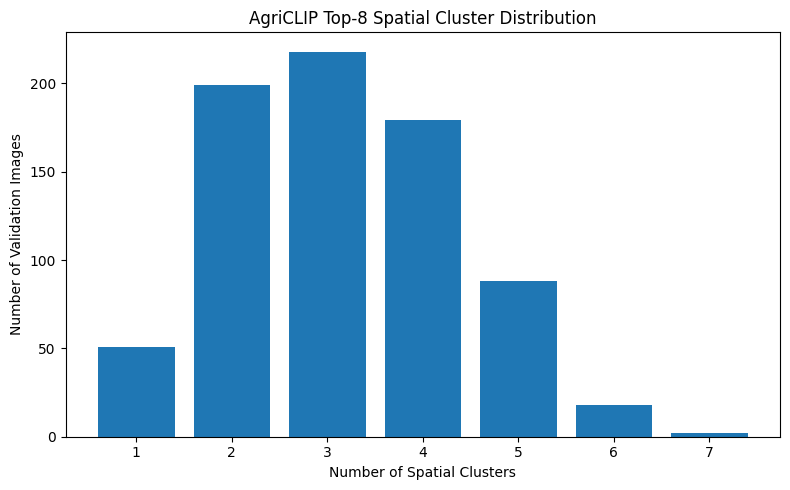

In [45]:
# ============================================================
# CLUSTER COUNT DISTRIBUTION
# ============================================================

cluster_counts = (
    results_df[
        "num_clusters"
    ]
    .value_counts()
    .sort_index()
)

print(
    cluster_counts
)

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.xlabel(
    "Number of Spatial Clusters"
)

plt.ylabel(
    "Number of Validation Images"
)

plt.title(
    f"AgriCLIP Top-{TOP_K} "
    "Spatial Cluster Distribution"
)

plt.tight_layout()
plt.show()

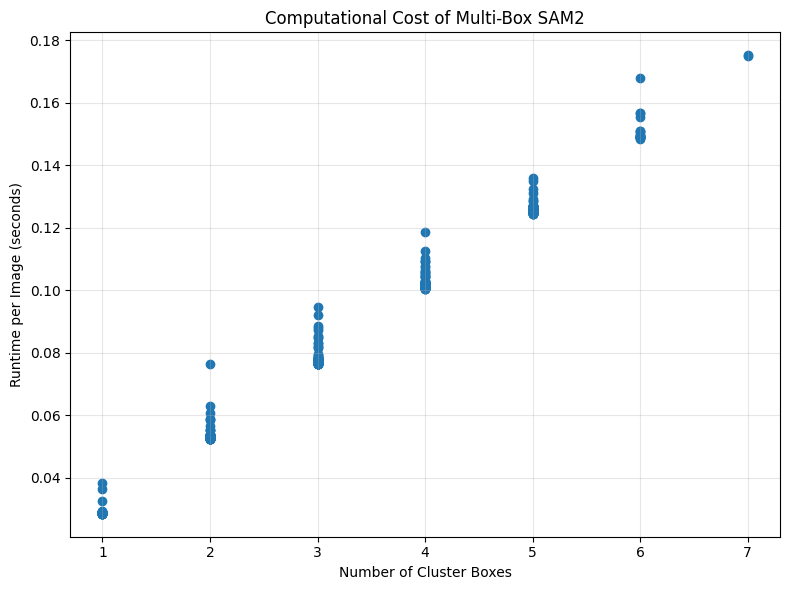

In [46]:
# ============================================================
# RUNTIME VS NUMBER OF CLUSTERS
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    results_df["num_clusters"],
    results_df["runtime_seconds"]
)

plt.xlabel(
    "Number of Cluster Boxes"
)

plt.ylabel(
    "Runtime per Image (seconds)"
)

plt.title(
    "Computational Cost of Multi-Box SAM2"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

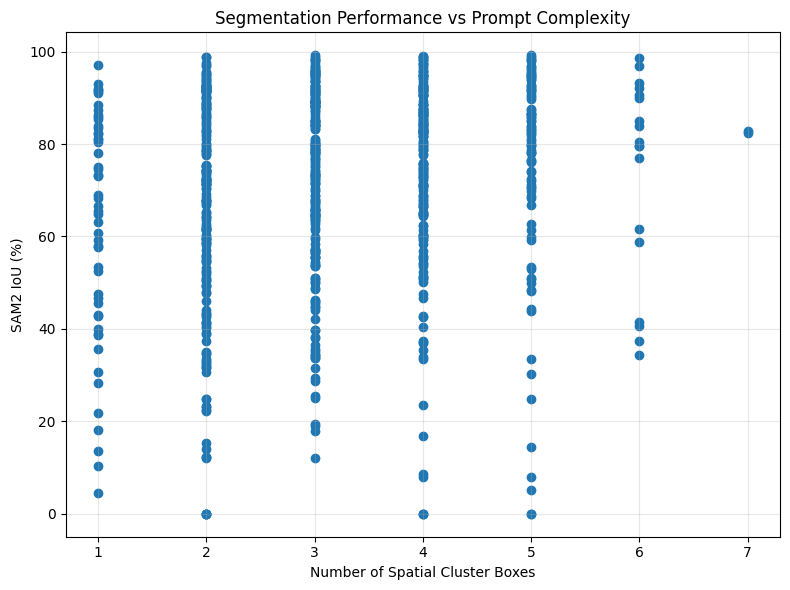

In [47]:
# ============================================================
# IOU VS NUMBER OF CLUSTERS
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    results_df["num_clusters"],
    results_df["iou"] * 100
)

plt.xlabel(
    "Number of Spatial Cluster Boxes"
)

plt.ylabel(
    "SAM2 IoU (%)"
)

plt.title(
    "Segmentation Performance vs Prompt Complexity"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

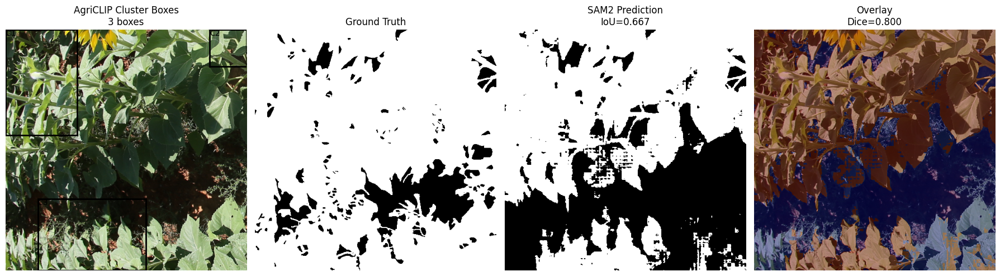

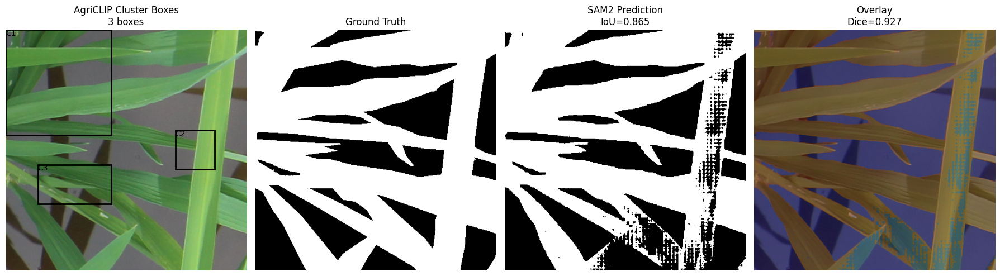

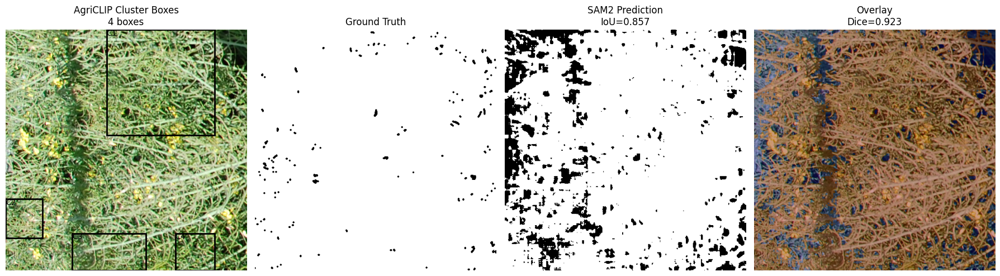

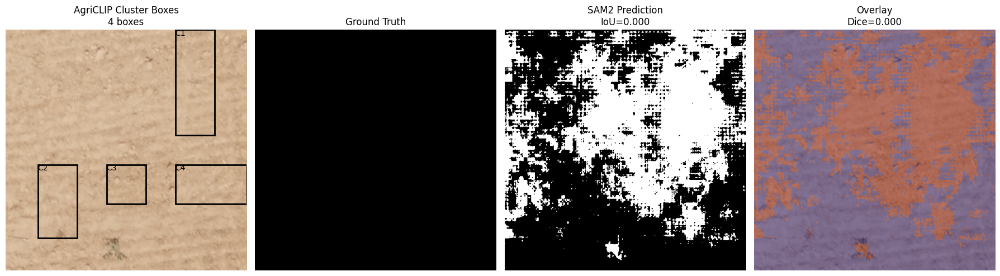

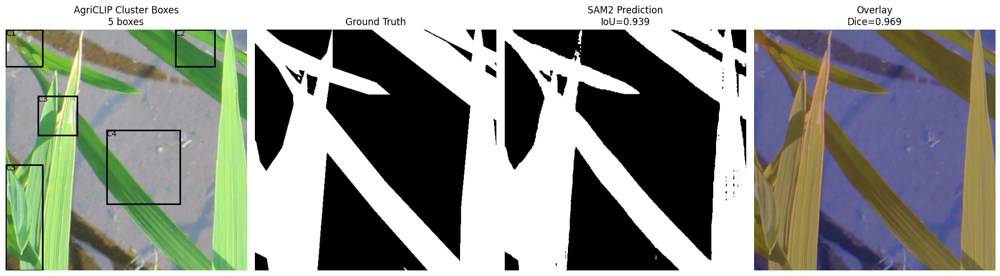

In [48]:
# ============================================================
# VISUALIZE RANDOM VALIDATION EXAMPLES
# ============================================================

random.seed(42)

sample_ids = random.sample(
    range(len(val_hf)),
    min(5, len(val_hf))
)

for idx in sample_ids:

    image = get_image(
        idx,
        split=val_hf
    )

    gt = get_mask(
        idx,
        split=val_hf
    )

    pred = cv2.imread(
        str(
            MASK_DIR /
            f"{idx:04d}.png"
        ),
        cv2.IMREAD_GRAYSCALE
    )

    pred = (
        pred // 255
    )

    boxes = np.load(
        BOX_DIR /
        f"{idx:04d}.npy"
    )

    row = results_df[
        results_df["image_id"] == idx
    ].iloc[0]

    fig, ax = plt.subplots(
        1,
        4,
        figsize=(18, 5)
    )

    # Image + boxes
    ax[0].imshow(image)

    for i, box in enumerate(
        boxes
    ):

        x1, y1, x2, y2 = box

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=2
        )

        ax[0].add_patch(
            rect
        )

        ax[0].text(
            x1,
            y1 + 12,
            f"C{i+1}"
        )

    ax[0].set_title(
        f"AgriCLIP Cluster Boxes\n"
        f"{len(boxes)} boxes"
    )

    ax[0].axis("off")

    # GT
    ax[1].imshow(
        gt,
        cmap="gray"
    )

    ax[1].set_title(
        "Ground Truth"
    )

    ax[1].axis("off")

    # Prediction
    ax[2].imshow(
        pred,
        cmap="gray"
    )

    ax[2].set_title(
        f"SAM2 Prediction\n"
        f"IoU={row['iou']:.3f}"
    )

    ax[2].axis("off")

    # Overlay
    ax[3].imshow(image)

    ax[3].imshow(
        pred,
        cmap="jet",
        alpha=0.4
    )

    ax[3].set_title(
        f"Overlay\n"
        f"Dice={row['dice']:.3f}"
    )

    ax[3].axis("off")

    plt.tight_layout()
    plt.show()

In [49]:
# ============================================================
# OLD VS NEW METHOD
# ============================================================

OLD_MERGED_BOX_IOU = 75.85
OLD_MERGED_BOX_DICE = 84.30

NEW_CLUSTER_IOU = (
    mean_results["iou"] * 100
)

NEW_CLUSTER_DICE = (
    mean_results["dice"] * 100
)

comparison = pd.DataFrame({

    "Method": [
        "AgriCLIP + SAM2\nSingle Merged Box",
        "AgriCLIP + SAM2\nSpatial Cluster Boxes"
    ],

    "IoU": [
        OLD_MERGED_BOX_IOU,
        NEW_CLUSTER_IOU
    ],

    "Dice": [
        OLD_MERGED_BOX_DICE,
        NEW_CLUSTER_DICE
    ]
})

comparison

,Method,IoU,Dice
0,AgriCLIP + SAM2\nSingle Merged Box,75.850000,84.300000
1,AgriCLIP + SAM2\nSpatial Cluster Boxes,70.619615,80.300909


In [50]:
# ============================================================
# OLD VS NEW METHOD
# ============================================================

OLD_MERGED_BOX_IOU = 75.85
OLD_MERGED_BOX_DICE = 84.30

NEW_CLUSTER_IOU = (
    mean_results["iou"] * 100
)

NEW_CLUSTER_DICE = (
    mean_results["dice"] * 100
)

comparison = pd.DataFrame({

    "Method": [
        "AgriCLIP + SAM2\nSingle Merged Box",
        "AgriCLIP + SAM2\nSpatial Cluster Boxes"
    ],

    "IoU": [
        OLD_MERGED_BOX_IOU,
        NEW_CLUSTER_IOU
    ],

    "Dice": [
        OLD_MERGED_BOX_DICE,
        NEW_CLUSTER_DICE
    ]
})

comparison

,Method,IoU,Dice
0,AgriCLIP + SAM2\nSingle Merged Box,75.850000,84.300000
1,AgriCLIP + SAM2\nSpatial Cluster Boxes,70.619615,80.300909


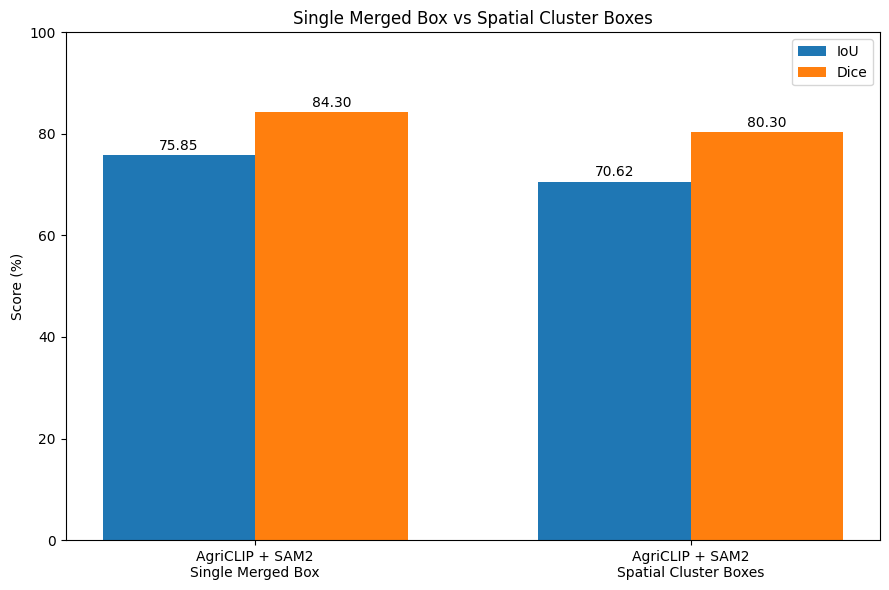

In [51]:
# ============================================================
# OLD VS NEW PLOT
# ============================================================

x = np.arange(
    len(comparison)
)

width = 0.35

plt.figure(
    figsize=(9, 6)
)

plt.bar(
    x - width / 2,
    comparison["IoU"],
    width,
    label="IoU"
)

plt.bar(
    x + width / 2,
    comparison["Dice"],
    width,
    label="Dice"
)

plt.xticks(
    x,
    comparison["Method"]
)

plt.ylabel(
    "Score (%)"
)

plt.ylim(
    0,
    100
)

plt.title(
    "Single Merged Box vs Spatial Cluster Boxes"
)

plt.legend()

for i in range(
    len(comparison)
):

    plt.text(
        i - width / 2,
        comparison["IoU"].iloc[i] + 1,
        f"{comparison['IoU'].iloc[i]:.2f}",
        ha="center"
    )

    plt.text(
        i + width / 2,
        comparison["Dice"].iloc[i] + 1,
        f"{comparison['Dice'].iloc[i]:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [52]:
# ============================================================
# SAVE EXPERIMENT CONFIGURATION
# ============================================================

config_path = (
    VAL_OUTPUT_DIR
    / "experiment_config.txt"
)

with open(
    config_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "AgriCLIP + SAM2 Spatial Cluster Boxes\n"
    )

    f.write(
        "Dataset: VegAnn\n"
    )

    f.write(
        f"Top-K: {TOP_K}\n"
    )

    f.write(
        f"Connectivity: {CONNECTIVITY}\n"
    )

    f.write(
        f"Margin: {MARGIN}\n"
    )

    f.write(
        f"Mask threshold: "
        f"{MASK_THRESHOLD}\n"
    )

    f.write(
        f"Number validation images: "
        f"{len(val_hf)}\n"
    )

    f.write(
        f"Mean SAM2 IoU: "
        f"{NEW_CLUSTER_IOU:.4f}\n"
    )

    f.write(
        f"Mean Dice: "
        f"{NEW_CLUSTER_DICE:.4f}\n"
    )

print(
    "Configuration saved:"
)

print(
    config_path
)

Configuration saved:
/home/zahranadeem/thesis/results/agriclip_cluster_boxes_vegann/validation/experiment_config.txt


In [54]:
#CLEANUO 
hook_handle.remove()

print("DINO Layer 4 REMOVED")

DINO Layer 4 REMOVED
